# Дополнительное задание к ЛР2. Классификация с кросс-валидацией

**Цель:** освоить обучение классификатора TensorFlow с пятикратной стратифицированной
кросс-валидацией, Grid Search и мониторингом TensorBoard.

Используется тот же Rice, что и в основной ЛР2. Код выполнен в похожем стиле:
последовательные шаги, две небольшие функции, словарь архитектур и обычные циклы.
Работа находится в отдельной папке и содержит свою копию данных.

План: подготовка → baseline → 5-fold CV → 3 × 3 Grid Search → кривые обучения →
сравнение конфигураций → финальная оценка и вывод.


Подключены те же основные библиотеки, что и во второй лабораторной.
`SEED=42`, детерминированный режим TensorFlow и два потока фиксируют условия расчётов.
В одном окружении результаты можно воспроизвести; время обучения зависит от компьютера.
40 эпох и batch=32 одинаковы для всех конфигураций. Результаты каждого запуска TensorBoard
попадают в отдельный каталог, поэтому повторное выполнение не смешивает события.

In [1]:
import os
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter
import json

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, ParameterGrid
from sklearn.metrics import accuracy_score, log_loss, ConfusionMatrixDisplay
from IPython.display import display, Markdown

SEED = 42
EPOCHS = 40
BATCH_SIZE = 32
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.config.experimental.enable_op_determinism()
tf.keras.utils.set_random_seed(SEED)
sns.set_theme(style='whitegrid')

BASE = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
if not (BASE / 'data/rice.csv').exists():
    BASE = BASE / 'lab2_extra'
RESULTS = BASE / 'results'
PLOTS = RESULTS / 'plots'
MODELS = RESULTS / 'models'
HISTORIES = RESULTS / 'histories'
for folder in [RESULTS, PLOTS, MODELS, HISTORIES]:
    folder.mkdir(parents=True, exist_ok=True)
LOGS = BASE / 'logs/tensorboard' / datetime.now(timezone.utc).strftime('%Y%m%d-%H%M%S-%fZ')

## 1. Загрузка и первичный анализ

Использован **тот же датасет, что и в ЛР2**:
[Rice (Cammeo and Osmancik), UCI](https://archive.ics.uci.edu/dataset/545/rice+cammeo+and+osmancik),
DOI [10.24432/C5MW4Z](https://doi.org/10.24432/C5MW4Z).
Локальная копия CSV, исходный ARFF и сведения о происхождении скопированы из `lab2/data`.
Расчёты работают без интернета.

3810 строк описывают зёрна риса. Входы: Area, Perimeter, Major_Axis_Length,
Minor_Axis_Length, Eccentricity, Convex_Area, Extent. Это семь числовых геометрических
признаков; `Class` — категориальная цель. Кодировка: Osmancik=0, Cammeo=1.

Пропусков и полных дубликатов в исходной копии нет. Классы: 2180 Osmancik (57.22%) и
1630 Cammeo (42.78%). Дисбаланс умеренный: сохраняем доли стратификацией, основной метрикой
оставляем accuracy; дополнительные веса классов и oversampling не применяем.
Категориальных входных признаков нет, поэтому one-hot encoding не требуется.
Числовые признаки далее стандартизируются: их масштабы существенно различаются.

In [2]:
df = pd.read_csv(BASE / 'data/rice.csv')
df.info()
print('Пропуски по столбцам:\n', df.isna().sum())
print('Полные дубликаты:', df.duplicated().sum())
X = df.drop(columns='Class')
y = df['Class'].map({'Osmancik': 0, 'Cammeo': 1})
if X.isna().any().any() or y.isna().any():
    raise ValueError('В данных появились пропуски или неизвестный класс: нужна предобработка.')
class_table = df['Class'].value_counts().rename('count').to_frame()
class_table['share'] = class_table['count'] / len(df)
display(class_table)
display(X.describe().round(3))
class_table.to_csv(RESULTS / 'class_distribution.csv')

<class 'pandas.DataFrame'>
RangeIndex: 3810 entries, 0 to 3809
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Area               3810 non-null   float64
 1   Perimeter          3810 non-null   float64
 2   Major_Axis_Length  3810 non-null   float64
 3   Minor_Axis_Length  3810 non-null   float64
 4   Eccentricity       3810 non-null   float64
 5   Convex_Area        3810 non-null   float64
 6   Extent             3810 non-null   float64
 7   Class              3810 non-null   str    
dtypes: float64(7), str(1)
memory usage: 238.3 KB
Пропуски по столбцам:
 Area                 0
Perimeter            0
Major_Axis_Length    0
Minor_Axis_Length    0
Eccentricity         0
Convex_Area          0
Extent               0
Class                0
dtype: int64
Полные дубликаты: 0


,count,share
Class,,
Osmancik,2180,0.572178
Cammeo,1630,0.427822


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent
count,3810.000,3810.000,3810.000,3810.000,3810.000,3810.000,3810.000
mean,12667.728,454.239,188.776,86.314,0.887,12952.497,0.662
std,1732.368,35.597,17.449,5.730,0.021,1776.972,0.077
min,7551.000,359.100,145.264,59.532,0.777,7723.000,0.497
25%,11370.500,426.145,174.354,82.732,0.872,11626.250,0.599
50%,12421.500,448.852,185.810,86.435,0.889,12706.500,0.645
75%,13950.000,483.684,203.550,90.144,0.903,14284.000,0.727
max,18913.000,548.446,239.010,107.542,0.948,19099.000,0.861


Распределения показывают различия размеров двух сортов и области их перекрытия.
Плотности нормированы отдельно по классу (`common_norm=False`). Последняя панель показывает
число объектов каждого класса. На этом этапе смотрим исходные данные;
параметры масштабирования здесь не вычисляются.

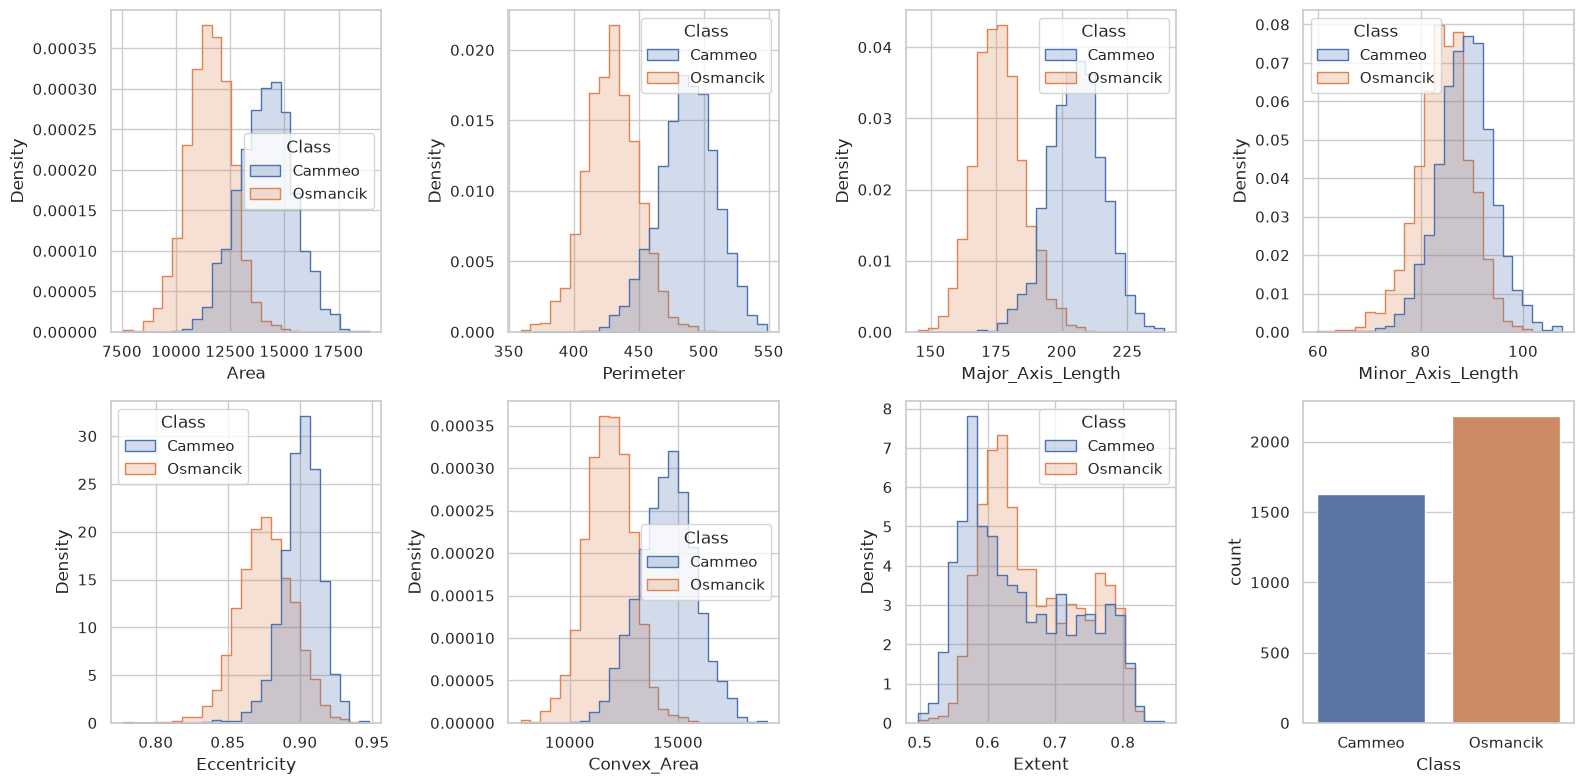

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, column in zip(axes.flat, X.columns):
    sns.histplot(data=df, x=column, hue='Class', bins=25, element='step',
                 stat='density', common_norm=False, ax=ax)
sns.countplot(data=df, x='Class', hue='Class', legend=False, ax=axes.flat[-1])
plt.tight_layout()
plt.savefig(PLOTS / '01_distributions.png', dpi=130)
plt.show()

## 2. Отложенная выборка и пять фолдов

Оставляем **20% (762 объекта)** в test, а **80% (3048 объектов)** используем для обучения
и Grid Search. Первое стратифицированное разбиение с seed=42 совпадает с ЛР2,
поэтому тестовые объекты те же. Здесь отдельный validation заменён пятикратной CV:
train и validation основной работы вместе образуют обучающие 80% дополнительной.

`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` создаёт пять постоянных фолдов.
Каждая строка обучающих 80% ровно один раз используется как validation и четыре раза —
для обучения. Разбиения одинаковы для всех девяти конфигураций.
Фолды содержат 609 или 610 объектов, обучающие части — 2439 или 2438.
Test ни в один фолд не попадает. Индексы и номера фолдов сохраняются в CSV.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train, y_train))
split_table = pd.DataFrame({'split': 'test', 'fold': 0}, index=X.index)
split_table.loc[X_train.index, 'split'] = 'train'
fold_rows = []
for fold, (train_index, val_index) in enumerate(folds, start=1):
    split_table.loc[X_train.iloc[val_index].index, 'fold'] = fold
    fold_rows.append({
        'fold': fold, 'train_size': len(train_index), 'val_size': len(val_index),
        'train_Cammeo_share': y_train.iloc[train_index].mean(),
        'val_Cammeo_share': y_train.iloc[val_index].mean(),
    })
split_table.to_csv(RESULTS / 'split_assignment.csv', index_label='row_id')
print('Train:', X_train.shape, 'Test:', X_test.shape)
display(pd.DataFrame(fold_rows))

Train: (3048, 7) Test: (762, 7)


,fold,train_size,val_size,train_Cammeo_share,val_Cammeo_share
0,1,2438,610,0.427810,0.427869
1,2,2438,610,0.427810,0.427869
2,3,2438,610,0.427810,0.427869
3,4,2439,609,0.428044,0.426929
4,5,2439,609,0.427634,0.428571


## 3. Нейросеть и метрики

Как в ЛР2, сеть создаётся небольшой функцией, а эксперименты выполняются обычными циклами.
Скрытые слои используют ReLU; выходной нейрон — sigmoid. Adam получает скорость обучения
явно. Loss — бинарная кросс-энтропия, метрика — accuracy при фиксированном пороге 0.5.

| Архитектура | Скрытые слои | Dropout | Параметров |
| :--- | :--- | :--- | ---: |
| dense16 | 16 | нет | 145 |
| dense32_16 | 32 → 16 | нет | 801 |
| dropout32_16 | 32 → 16 | 0.25 после каждого слоя | 801 |

`calculate_metrics` одинаково рассчитывает accuracy и log loss по вероятностям.
Dropout выключен при `predict`, поэтому итоговое сравнение train/validation производится
в одном режиме. Логируемый training loss в процессе fit у dropout-сети получен с активным dropout.

In [5]:
# Название архитектуры: скрытые слои и доля dropout после каждого скрытого слоя.
architectures = {
    'dense16': ((16,), 0.0),
    'dense32_16': ((32, 16), 0.0),
    'dropout32_16': ((32, 16), 0.25),
}


def create_network(architecture, learning_rate):
    layers, dropout = architectures[architecture]
    network = tf.keras.Sequential([tf.keras.Input(shape=(X.shape[1],))])
    for neurons in layers:
        network.add(tf.keras.layers.Dense(neurons, activation='relu'))
        if dropout > 0:
            network.add(tf.keras.layers.Dropout(dropout))
    network.add(tf.keras.layers.Dense(1, activation='sigmoid'))
    network.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                    loss='binary_crossentropy', metrics=['accuracy'])
    return network


def calculate_metrics(y_true, scores):
    return {'accuracy': accuracy_score(y_true, scores >= 0.5),
            'loss': log_loss(y_true, scores, labels=[0, 1])}


create_network('dense16', 0.001).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 145 (580.00 B)

 Trainable params: 145 (580.00 B)

 Non-trainable params: 0 (0.00 B)

## 4. Baseline

Baseline повторяет простую сеть второй лабораторной: **7 → 16 → 1**, ReLU,
Adam(lr=0.001), 40 эпох, batch=32. Сначала фиксируем её accuracy на test.
Эта оценка служит точкой отсчёта и не участвует в выборе параметров.

Scaler обучается на всех 3048 обучающих объектах. К test применяется только `transform`.
Для финальной сети будут использованы тот же train, scaler, seed, число эпох и batch.
Таким образом, сравнение показывает эффект выбранных lr и архитектуры при равном объёме данных.
Test не передаётся в fit даже как validation. У baseline и финального обучения
в TensorBoard есть train-кривые, а у каждого CV-фолда — train и validation.

In [6]:
# Одинаковый train для baseline и финальной модели; test не влияет на подбор.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype('float32')
X_test_scaled = scaler.transform(X_test).astype('float32')
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
baseline = create_network('dense16', 0.001)
started = perf_counter()
baseline_history = baseline.fit(
    X_train_scaled, y_train.to_numpy(), epochs=EPOCHS, batch_size=BATCH_SIZE,
    callbacks=[tf.keras.callbacks.TensorBoard(log_dir=str(LOGS / 'baseline'),
                                             write_graph=False, profile_batch=0)], verbose=0,
)
baseline_seconds = perf_counter() - started
baseline_scores = baseline.predict(X_test_scaled, verbose=0).ravel()
baseline_metrics = calculate_metrics(y_test, baseline_scores)
pd.DataFrame(baseline_history.history).to_csv(HISTORIES / 'baseline.csv', index_label='epoch0')
pd.DataFrame([{'model': 'Baseline', **baseline_metrics, 'fit_seconds': baseline_seconds}]).to_csv(
    RESULTS / 'baseline_metrics.csv', index=False
)
baseline.save(MODELS / 'baseline.keras')
joblib.dump(scaler, MODELS / 'scaler.joblib')
print('Baseline: dense16, Adam(lr=0.001), 40 эпох, batch=32')
print('Test:', baseline_metrics, 'Время обучения:', round(baseline_seconds, 2), 'с')

Baseline: dense16, Adam(lr=0.001), 40 эпох, batch=32
Test: {'accuracy': 0.9173228346456693, 'loss': 0.19274680316448212} Время обучения: 6.87 с


## 5. Сетка гиперпараметров

Проверяются **три learning rate: 0.0001, 0.001, 0.01** и **три архитектуры**.
`ParameterGrid` строит декартово произведение: 3 × 3 = 9 конфигураций.
Каждая оценивается на пяти фолдах, итого **45 обучений**.
Вместе с baseline и финальной сетью — 47 запусков.

Это полный Grid Search с CV, реализованный явно, чтобы было видно обучение scaler,
создание новой модели и подключение TensorBoard на каждом фолде.
Дополнительные обёртки Keras для Scikit-Learn не нужны.
Все конфигурации обучаются до 40-й эпохи; EarlyStopping и выбор эпохи по validation
не используются. Сравниваются веса последней эпохи.

In [7]:
param_grid = {
    'learning_rate': [0.0001, 0.001, 0.01],
    'architecture': list(architectures),
}
configurations = list(ParameterGrid(param_grid))
print('Конфигураций:', len(configurations))
print('Обучений в CV:', len(configurations) * len(folds))
display(pd.DataFrame(configurations))

Конфигураций: 9
Обучений в CV: 45


,architecture,learning_rate
0,dense16,0.0001
1,dense16,0.0010
2,dense16,0.0100
3,dense32_16,0.0001
4,dense32_16,0.0010
5,dense32_16,0.0100
6,dropout32_16,0.0001
7,dropout32_16,0.0010
8,dropout32_16,0.0100


## 6. Пятикратная кросс-валидация и TensorBoard

Для каждой пары «конфигурация, фолд» создаются **новые scaler, сеть и оптимизатор**.
Средние и стандартные отклонения признаков вычисляются только по обучающей части
текущего фолда. Валидационная часть проходит только transform — утечки данных нет.
Масштабированные для baseline данные в CV не используются.

На одном фолде разные конфигурации получают одинаковый seed=42+номер фолда.
Между фолдами меняются и объекты, и инициализация; разброс описывает эти условия.
Записываются accuracy, loss, время fit, train/validation размеры, число параметров,
история каждой эпохи и OOF-вероятности (прогнозы для объектов, не участвовавших
в обучении соответствующей сети).

Callback TensorBoard получает каталог `конфигурация/fold_N`. Внутри него `train` и
`validation` содержат `epoch_accuracy` и `epoch_loss` — четыре нужные кривые.
Время охватывает fit вместе с validation и TensorBoard; предобработка и predict не входят.
Весь перебор на CPU может занять несколько минут.

In [8]:
# Полный Grid Search: каждое сочетание параметров обучается на всех пяти фолдах.
cv_rows, histories = [], {}
oof = pd.DataFrame({'y_true': y_train, 'fold': split_table.loc[X_train.index, 'fold']})
for params in configurations:
    architecture = params['architecture']
    learning_rate = params['learning_rate']
    run = f'{architecture}_lr{learning_rate:g}'
    oof[run] = np.nan
    for fold, (train_index, val_index) in enumerate(folds, start=1):
        X_fold_train, X_fold_val = X_train.iloc[train_index], X_train.iloc[val_index]
        y_fold_train, y_fold_val = y_train.iloc[train_index], y_train.iloc[val_index]
        # Scaler заново обучается только на обучающей части текущего фолда.
        fold_scaler = StandardScaler()
        X_fold_train_scaled = fold_scaler.fit_transform(X_fold_train).astype('float32')
        X_fold_val_scaled = fold_scaler.transform(X_fold_val).astype('float32')
        tf.keras.backend.clear_session()
        # Для разных конфигураций seed на одном фолде одинаков, между фолдами различен.
        tf.keras.utils.set_random_seed(SEED + fold)
        network = create_network(architecture, learning_rate)
        tensorboard = tf.keras.callbacks.TensorBoard(
            log_dir=str(LOGS / run / f'fold_{fold}'), write_graph=False, profile_batch=0,
        )
        started = perf_counter()
        history = network.fit(
            X_fold_train_scaled, y_fold_train.to_numpy(),
            validation_data=(X_fold_val_scaled, y_fold_val.to_numpy()),
            epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=[tensorboard], verbose=0,
        )
        fit_seconds = perf_counter() - started
        train_scores = network.predict(X_fold_train_scaled, verbose=0).ravel()
        val_scores = network.predict(X_fold_val_scaled, verbose=0).ravel()
        train_metrics = calculate_metrics(y_fold_train, train_scores)
        val_metrics = calculate_metrics(y_fold_val, val_scores)
        oof.loc[X_fold_val.index, run] = val_scores
        history_table = pd.DataFrame(history.history)
        history_table.index = np.arange(1, EPOCHS + 1)
        history_table.index.name = 'epoch'
        histories[(run, fold)] = history_table
        history_table.to_csv(HISTORIES / f'{run}_fold{fold}.csv')
        cv_rows.append({
            'run': run, **params, 'fold': fold, 'parameters': network.count_params(),
            'train_size': len(train_index), 'val_size': len(val_index),
            'train_accuracy': train_metrics['accuracy'], 'train_loss': train_metrics['loss'],
            'val_accuracy': val_metrics['accuracy'], 'val_loss': val_metrics['loss'],
            'fit_seconds': fit_seconds,
        })
        print(f'{run}, fold {fold}/5: accuracy={val_metrics["accuracy"]:.5f}, '
              f'loss={val_metrics["loss"]:.5f}, {fit_seconds:.1f} с', flush=True)
        # Промежуточное сохранение: уже рассчитанные фолды остаются на диске.
        pd.DataFrame(cv_rows).to_csv(RESULTS / 'cv_folds.csv', index=False)
        oof.to_csv(RESULTS / 'oof_predictions.csv', index_label='row_id')
cv_table = pd.DataFrame(cv_rows)

dense16_lr0.0001, fold 1/5: accuracy=0.93443, loss=0.18902, 8.0 с


dense16_lr0.0001, fold 2/5: accuracy=0.92623, loss=0.20985, 8.1 с


dense16_lr0.0001, fold 3/5: accuracy=0.92131, loss=0.22263, 7.8 с


dense16_lr0.0001, fold 4/5: accuracy=0.94089, loss=0.16886, 8.1 с


dense16_lr0.0001, fold 5/5: accuracy=0.90805, loss=0.24142, 7.3 с


dense16_lr0.001, fold 1/5: accuracy=0.94098, loss=0.17680, 8.1 с


... (35 outputs left out)

dropout32_16_lr0.01, fold 2/5: accuracy=0.92623, loss=0.19589, 12.3 с


dropout32_16_lr0.01, fold 3/5: accuracy=0.93443, loss=0.19001, 10.1 с


dropout32_16_lr0.01, fold 4/5: accuracy=0.93268, loss=0.16853, 11.8 с


dropout32_16_lr0.01, fold 5/5: accuracy=0.91790, loss=0.22040, 10.2 с


## 7. Сравнение девяти конфигураций

Главный критерий — **максимальная средняя validation accuracy пяти фолдов**.
При точном равенстве выбираем меньший std, затем меньший loss, затем меньшее число
параметров; последний технический критерий — имя конфигурации.
Это правило фиксировано до просмотра test. Время обучения показано отдельно:
оно зависит от оборудования и не используется для выбора при близких результатах.

Таблица содержит средние и **выборочные std (ddof=1)** accuracy/loss, время,
число параметров, train-метрики и разрыв train−validation accuracy.
Пять фолдов имеют почти равный размер, поэтому используем обычное среднее.
Std показывает устойчивость к фолдам и инициализации; это не доверительный интервал.
Малые различия качества сами по себе не устанавливают статистическое превосходство.

,run,architecture,learning_rate,mean_accuracy,std_accuracy,mean_loss,std_loss,mean_train_accuracy,mean_train_loss,mean_fit_seconds,total_fit_seconds,parameters,accuracy_gap
0,dense16_lr0.001,dense16,0.0010,0.93044,0.01119,0.18272,0.02150,0.93151,0.17910,8.27783,41.38917,145,0.00107
1,dropout32_16_lr0.01,dropout32_16,0.0100,0.93011,0.00829,0.19107,0.01939,0.93381,0.17725,11.77895,58.89475,801,0.00369
2,dropout32_16_lr0.001,dropout32_16,0.0010,0.92979,0.00997,0.18465,0.02239,0.93340,0.17731,9.65677,48.28383,801,0.00361
3,dense32_16_lr0.0001,dense32_16,0.0001,0.92913,0.01273,0.18418,0.02269,0.93094,0.18119,9.29025,46.45127,801,0.00180
4,dense16_lr0.01,dense16,0.0100,0.92880,0.00913,0.18637,0.02142,0.93299,0.17720,8.47854,42.39272,145,0.00419
5,dense32_16_lr0.001,dense32_16,0.0010,0.92815,0.01042,0.18564,0.02178,0.93356,0.17515,8.81820,44.09099,801,0.00542
6,dense32_16_lr0.01,dense32_16,0.0100,0.92782,0.00509,0.19684,0.01659,0.93315,0.17095,8.98872,44.94358,801,0.00533
7,dropout32_16_lr0.0001,dropout32_16,0.0001,0.92749,0.01163,0.18483,0.02279,0.92897,0.18305,8.35760,41.78802,801,0.00148
8,dense16_lr0.0001,dense16,0.0001,0.92618,0.01262,0.20636,0.02834,0.92511,0.20795,7.85535,39.27674,145,-0.00107


Выбрано только по CV: dense16_lr0.001
CV accuracy = 0.93044 ± 0.01119 (std)


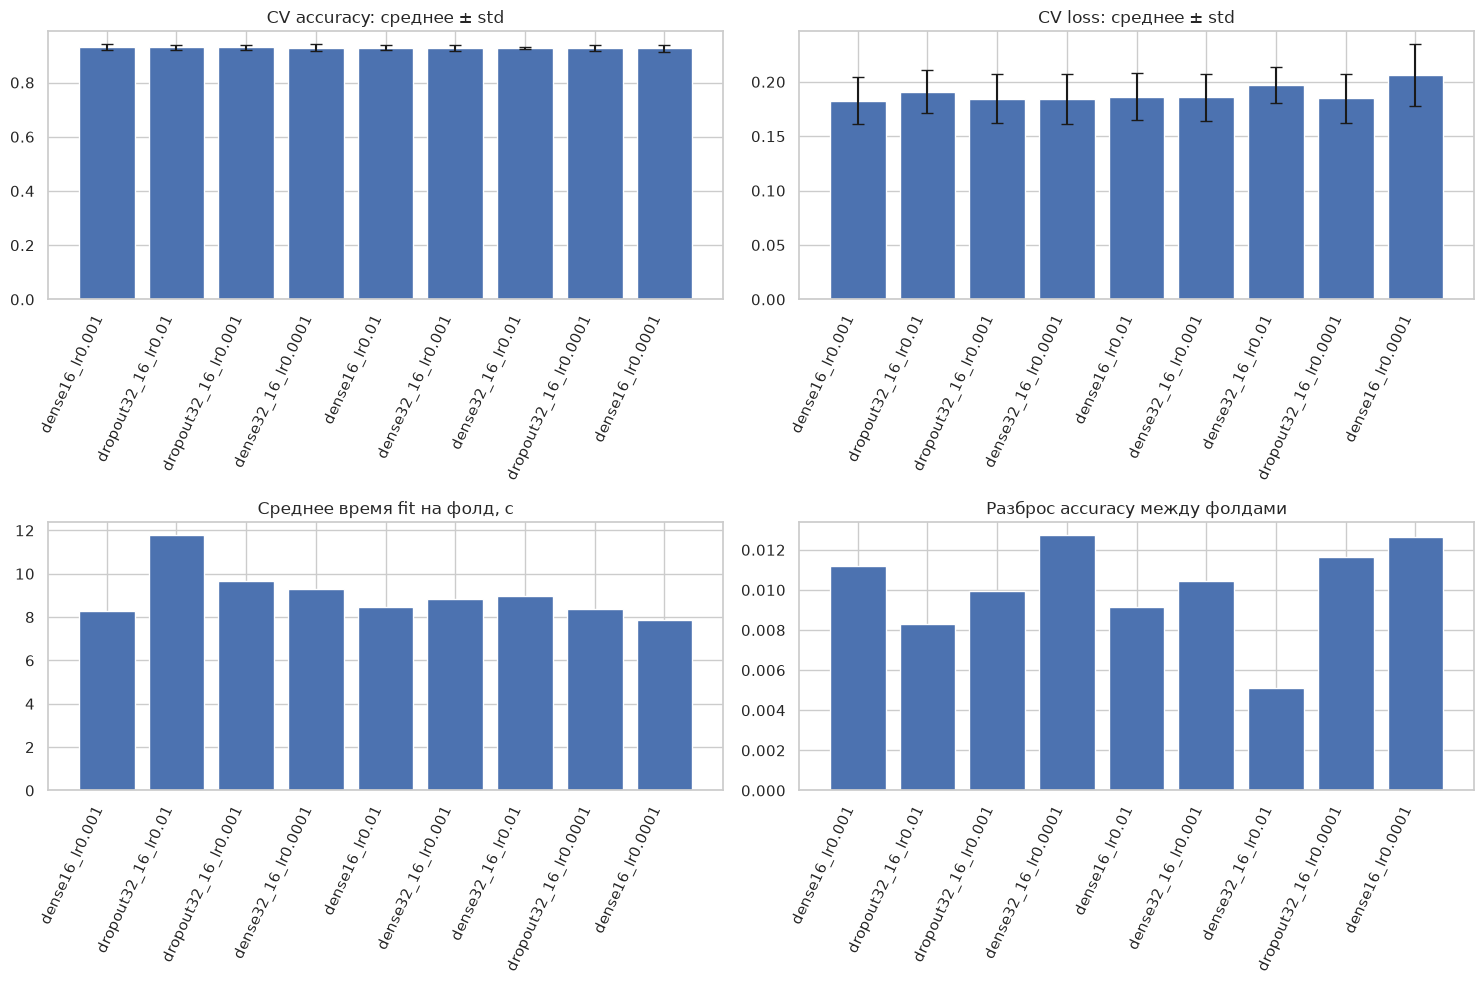

In [9]:
summary = cv_table.groupby(['run', 'architecture', 'learning_rate'], as_index=False).agg(
    mean_accuracy=('val_accuracy', 'mean'), std_accuracy=('val_accuracy', 'std'),
    mean_loss=('val_loss', 'mean'), std_loss=('val_loss', 'std'),
    mean_train_accuracy=('train_accuracy', 'mean'), mean_train_loss=('train_loss', 'mean'),
    mean_fit_seconds=('fit_seconds', 'mean'), total_fit_seconds=('fit_seconds', 'sum'),
    parameters=('parameters', 'first'),
)
summary['accuracy_gap'] = summary['mean_train_accuracy'] - summary['mean_accuracy']
# При точном равенстве accuracy: меньше разброс, loss, число параметров, затем имя.
summary = summary.sort_values(
    ['mean_accuracy', 'std_accuracy', 'mean_loss', 'parameters', 'run'],
    ascending=[False, True, True, True, True],
).reset_index(drop=True)
summary.to_csv(RESULTS / 'cv_results.csv', index=False)
best = summary.iloc[0]
best_run = best['run']
display(summary.round(5))
print('Выбрано только по CV:', best_run)
print(f'CV accuracy = {best["mean_accuracy"]:.5f} ± {best["std_accuracy"]:.5f} (std)')

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
positions = np.arange(len(summary))
for ax, column, error, title in [
    (axes[0, 0], 'mean_accuracy', 'std_accuracy', 'CV accuracy: среднее ± std'),
    (axes[0, 1], 'mean_loss', 'std_loss', 'CV loss: среднее ± std'),
    (axes[1, 0], 'mean_fit_seconds', None, 'Среднее время fit на фолд, с'),
    (axes[1, 1], 'std_accuracy', None, 'Разброс accuracy между фолдами'),
]:
    ax.bar(positions, summary[column], yerr=summary[error] if error else None, capsize=4)
    ax.set_xticks(positions, summary['run'], rotation=65, ha='right')
    ax.set_title(title)
plt.tight_layout()
plt.savefig(PLOTS / '02_configurations.png', dpi=130)
plt.show()

## 8. Кривые обучения и мониторинг

На первых двух рисунках представлены **все девять конфигураций**:
средние train/validation loss и accuracy по пяти фолдам, полоса ±1 std.
Третий рисунок раскрывает validation-кривые каждого фолда победителя.
Так можно сравнить скорость сходимости, устойчивость и расхождение train/validation.

При слишком малом lr к 40-й эпохе возможно недообучение. При слишком большом lr
возможны колебания loss. Падение train loss вместе с ростом validation loss может
указывать на переобучение. У dropout train-кривые включают случайное выключение
нейронов, поэтому train accuracy может быть ниже validation accuracy.
Для окончательного разрыва train/validation в таблице использован `predict` без dropout.

Для просмотра настоящих событий из корня проекта:

```bash
lab2/.venv/bin/tensorboard --logdir lab2_extra/logs/tensorboard --port 6006
```

Открыть http://localhost:6006. В Time Series / Scalars выбрать `epoch_accuracy` и
`epoch_loss`, затем сравнить `train` и `validation` нужных конфигураций и фолдов.
Каталог текущего запуска также записывается в `results/run_info.json`.

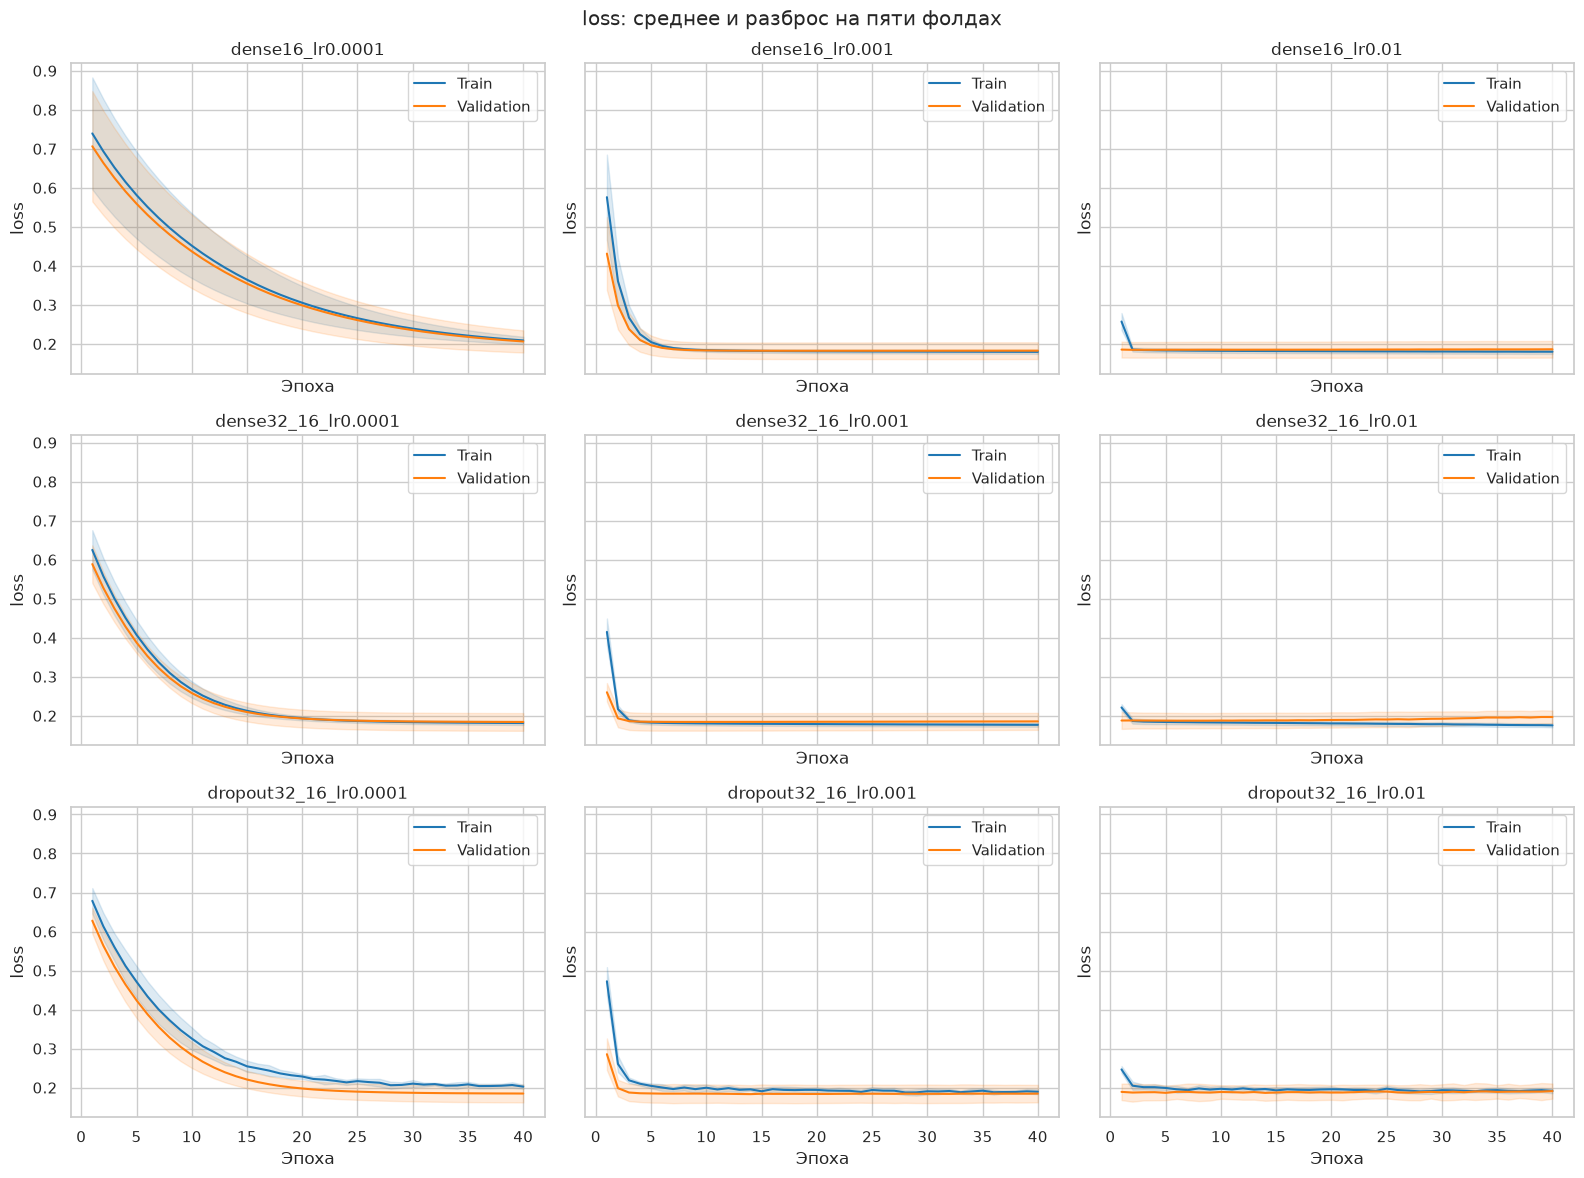

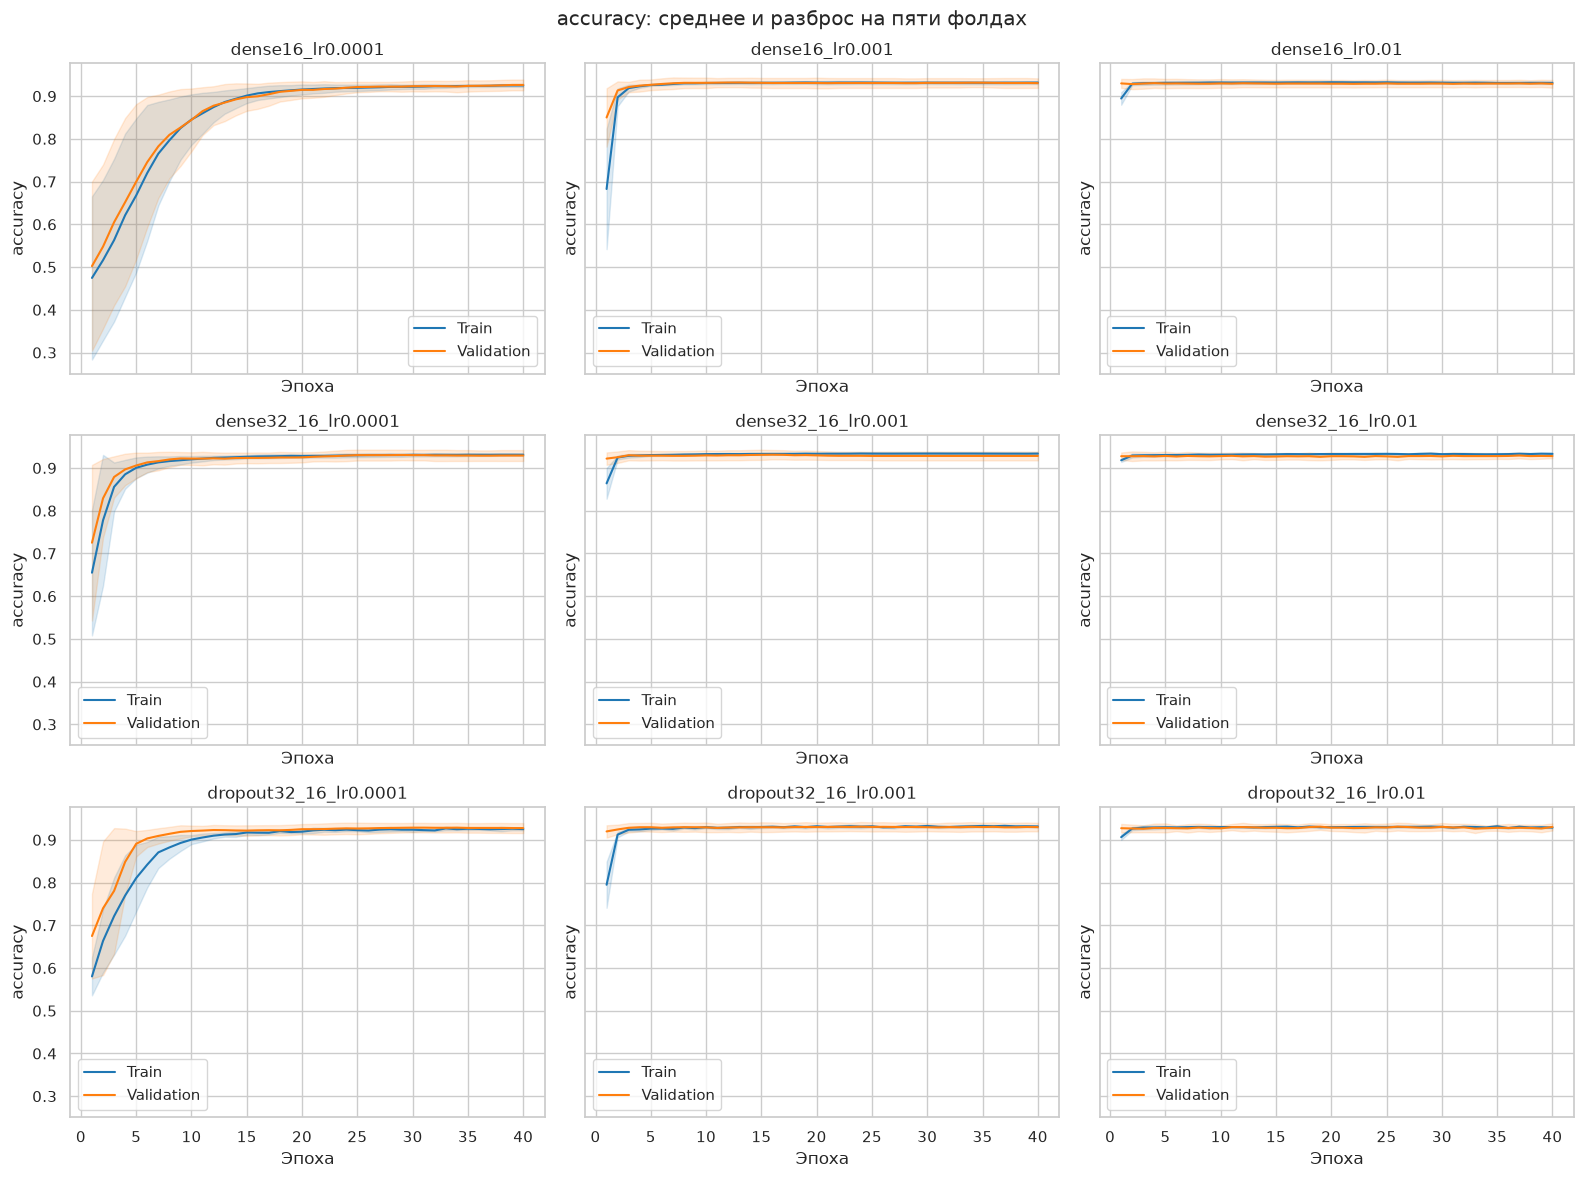

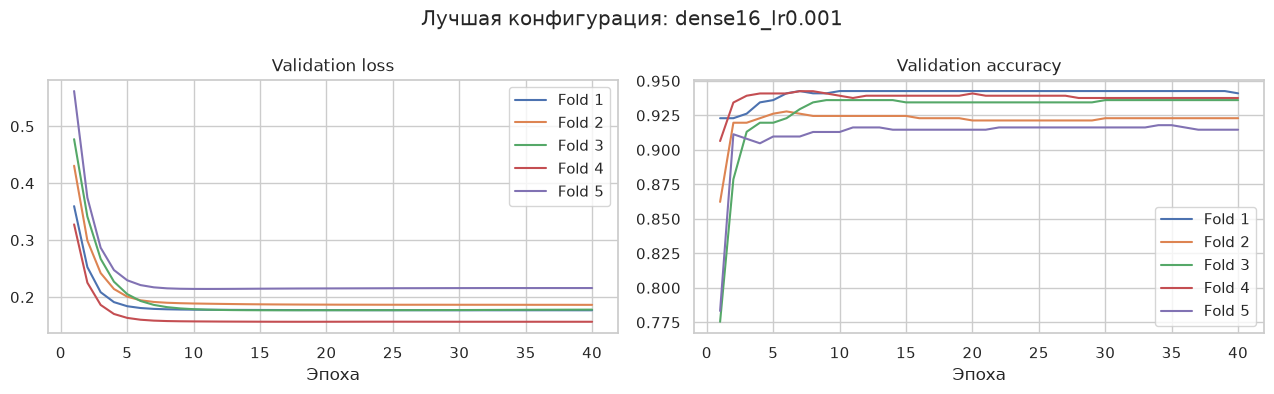

In [10]:
# Среднее по пяти фолдам и полоса ±1 std; для dropout train измеряется с активным dropout.
for metric in ['loss', 'accuracy']:
    fig, axes = plt.subplots(3, 3, figsize=(16, 12), sharex=True, sharey=True)
    for ax, params in zip(axes.flat, configurations):
        run = f'{params["architecture"]}_lr{params["learning_rate"]:g}'
        for prefix, label, color in [('', 'Train', 'tab:blue'), ('val_', 'Validation', 'tab:orange')]:
            curves = np.array([histories[(run, fold)][prefix + metric] for fold in range(1, 6)])
            mean, std = curves.mean(axis=0), curves.std(axis=0, ddof=1)
            epochs = np.arange(1, EPOCHS + 1)
            ax.plot(epochs, mean, label=label, color=color)
            ax.fill_between(epochs, mean - std, mean + std, alpha=0.15, color=color)
        ax.set(title=run, xlabel='Эпоха', ylabel=metric)
        ax.legend()
    plt.suptitle(f'{metric}: среднее и разброс на пяти фолдах')
    plt.tight_layout()
    plt.savefig(PLOTS / f'03_learning_{metric}.png', dpi=130)
    plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for fold in range(1, 6):
    history = histories[(best_run, fold)]
    for ax, metric in zip(axes, ['loss', 'accuracy']):
        ax.plot(history.index, history['val_' + metric], label=f'Fold {fold}')
        ax.set(title=f'Validation {metric}', xlabel='Эпоха')
        ax.legend()
plt.suptitle(f'Лучшая конфигурация: {best_run}')
plt.tight_layout()
plt.savefig(PLOTS / '04_best_folds.png', dpi=130)
plt.show()

## 9. Влияние learning rate и архитектуры

Тепловая карта показывает полную сетку: в каждой ячейке средняя accuracy пяти фолдов.
Дополнительно для каждого значения фактора accuracy усредняется по трём значениям
другого фактора. Размах этих средних позволяет описательно сравнить силу влияния
скорости обучения и архитектуры **в пределах проверенной сетки**.
Эти усреднения не учитывают взаимодействия, поэтому читаются вместе с тепловой картой.
Сравнение dense32_16 и dropout32_16 при одном lr позволяет отдельно посмотреть dropout;
переход от dense16 к dense32_16 одновременно меняет ширину и глубину.

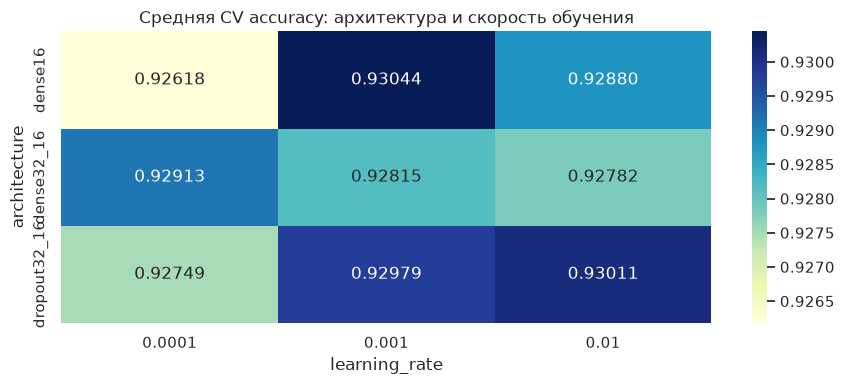

,factor,value,mean_accuracy
0,learning_rate,0.0001,0.927602
1,learning_rate,0.001,0.929459
2,learning_rate,0.01,0.928913
3,architecture,dense16,0.928475
4,architecture,dense32_16,0.928367
5,architecture,dropout32_16,0.929132


Размах средних по learning_rate: 0.186 п.п.
Размах средних по архитектуре: 0.077 п.п.


In [11]:
heatmap = summary.pivot(index='architecture', columns='learning_rate', values='mean_accuracy')
plt.figure(figsize=(9, 4))
sns.heatmap(heatmap, annot=True, fmt='.5f', cmap='YlGnBu')
plt.title('Средняя CV accuracy: архитектура и скорость обучения')
plt.tight_layout()
plt.savefig(PLOTS / '05_parameter_effects.png', dpi=130)
plt.show()

effects = []
for factor in ['learning_rate', 'architecture']:
    means = summary.groupby(factor)['mean_accuracy'].mean()
    for value, mean in means.items():
        effects.append({'factor': factor, 'value': str(value), 'mean_accuracy': mean})
effects = pd.DataFrame(effects)
effects.to_csv(RESULTS / 'parameter_effects.csv', index=False)
display(effects)
lr_range = summary.groupby('learning_rate')['mean_accuracy'].mean().pipe(lambda s: s.max() - s.min())
architecture_range = summary.groupby('architecture')['mean_accuracy'].mean().pipe(lambda s: s.max() - s.min())
print(f'Размах средних по learning_rate: {100 * lr_range:.3f} п.п.')
print(f'Размах средних по архитектуре: {100 * architecture_range:.3f} п.п.')

## 10. Финальное обучение и оценка

Победитель уже выбран по CV. Создаём сеть заново и обучаем на **всех 3048 объектах train**.
Используем scaler baseline, обученный на той же полной обучающей части.
Все параметры, включая 40 эпох и порог 0.5, зафиксированы до оценки test.

Обе модели проверяются на одних 762 тестовых объектах. Показаны accuracy,
binary log loss и время fit; разница accuracy выражается в процентных пунктах.
Сохраняются вероятности и метки каждого объекта, чтобы результат можно было проверить.
Если test accuracy не улучшилась, это тоже содержательный результат:
CV-оптимизация не гарантирует улучшения на каждом отдельном test.

In [12]:
# Архитектура, lr и число эпох уже зафиксированы. Test в fit не передаётся.
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
final_network = create_network(best['architecture'], float(best['learning_rate']))
started = perf_counter()
final_history = final_network.fit(
    X_train_scaled, y_train.to_numpy(), epochs=EPOCHS, batch_size=BATCH_SIZE,
    callbacks=[tf.keras.callbacks.TensorBoard(log_dir=str(LOGS / 'final'),
                                             write_graph=False, profile_batch=0)], verbose=0,
)
final_seconds = perf_counter() - started
final_scores = final_network.predict(X_test_scaled, verbose=0).ravel()
final_metrics = calculate_metrics(y_test, final_scores)
final_network.save(MODELS / 'best.keras')
pd.DataFrame(final_history.history).to_csv(HISTORIES / 'final.csv', index_label='epoch0')
test_table = pd.DataFrame([
    {'model': 'Baseline', 'configuration': 'dense16_lr0.001', **baseline_metrics,
     'fit_seconds': baseline_seconds},
    {'model': 'Tuned MLP', 'configuration': best_run, **final_metrics,
     'fit_seconds': final_seconds},
])
test_table.to_csv(RESULTS / 'test_metrics.csv', index=False)
predictions = pd.DataFrame({
    'row_id': X_test.index, 'y_true': y_test.to_numpy(),
    'baseline_score': baseline_scores, 'baseline_prediction': (baseline_scores >= 0.5).astype(int),
    'tuned_score': final_scores, 'tuned_prediction': (final_scores >= 0.5).astype(int),
})
predictions.to_csv(RESULTS / 'test_predictions.csv', index=False)
display(test_table.round(5))
print(f'Изменение test accuracy: {100 * (final_metrics["accuracy"] - baseline_metrics["accuracy"]):+.3f} п.п.')

,model,configuration,accuracy,loss,fit_seconds
0,Baseline,dense16_lr0.001,0.91732,0.19275,6.87224
1,Tuned MLP,dense16_lr0.001,0.91732,0.19275,12.27722


Изменение test accuracy: +0.000 п.п.


Матрицы ошибок показывают, какие сорта путают baseline и выбранная сеть.
Строки — истинные классы, столбцы — предсказания; порядок Osmancik, Cammeo.
Они дополняют общую accuracy числом ложных решений для каждого сорта.

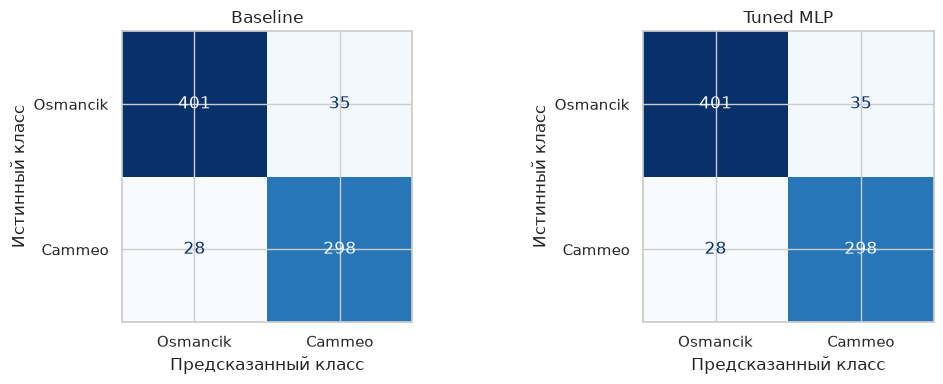

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name, scores in zip(axes, ['Baseline', 'Tuned MLP'], [baseline_scores, final_scores]):
    ConfusionMatrixDisplay.from_predictions(y_test, scores >= 0.5,
        display_labels=['Osmancik', 'Cammeo'], cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')
plt.tight_layout()
plt.savefig(PLOTS / '06_confusion.png', dpi=130)
plt.show()

## 11. Выводы по рассчитанным результатам

Следующая ячейка формирует численный вывод из таблиц текущего запуска, поэтому
показатели обновятся при повторном выполнении. Дополнительно вывод сохраняется
в `results/conclusion.md`. Выбор победителя по CV фиксируется независимо от test.
Высокая CV accuracy после перебора может быть оптимистичной; независимый test
даёт итоговую оценку, а повторные разбиения потребовались бы для более строгого вывода.

In [14]:
baseline_cv = summary.loc[summary['run'] == 'dense16_lr0.001'].iloc[0]
delta = 100 * (final_metrics['accuracy'] - baseline_metrics['accuracy'])
stronger = 'скорость обучения' if lr_range > architecture_range else 'архитектура'
best_history = pd.concat([histories[(best_run, fold)] for fold in range(1, 6)]).groupby('epoch').mean()
minimum_loss_epoch = int(best_history['val_loss'].idxmin())
conclusion = f'''## Итоговые результаты

- Данные: {len(df)} объектов, {X.shape[1]} числовых признаков, два класса.
  Train — {len(X_train)}, test — {len(X_test)}. Проверены 9 конфигураций × 5 фолдов.
- Baseline: **dense16, lr=0.001**; test accuracy **{baseline_metrics['accuracy']:.5f}**,
  test loss **{baseline_metrics['loss']:.5f}**.
- Лучшая конфигурация по CV: **{best_run}**; средняя accuracy
  **{best['mean_accuracy']:.5f} ± {best['std_accuracy']:.5f}** (выборочное std, 5 фолдов),
  средний loss **{best['mean_loss']:.5f}**, среднее время fit **{best['mean_fit_seconds']:.2f} с/фолд**.
- Для исходной конфигурации CV accuracy равна **{baseline_cv['mean_accuracy']:.5f}**;
  прирост после подбора на CV — **{100 * (best['mean_accuracy'] - baseline_cv['mean_accuracy']):+.3f} п.п.**
- После обучения лучшей конфигурации на всём train: test accuracy
  **{final_metrics['accuracy']:.5f}**, test loss **{final_metrics['loss']:.5f}**.
  Изменение test accuracy относительно baseline: **{delta:+.3f} п.п.**
- В выбранной сетке сильнее повлияла **{stronger}**: размах средних accuracy
  по learning rate — **{100 * lr_range:.3f} п.п.**, по архитектуре — **{100 * architecture_range:.3f} п.п.**
  Это описательное сравнение усреднений по остальным настройкам; взаимодействия видны на тепловой карте.
- Разрыв между train и validation accuracy у победителя: **{100 * best['accuracy_gap']:.3f} п.п.**
  Минимум усреднённого validation loss достигнут на эпохе **{minimum_loss_epoch}**;
  оценивались веса последней, {EPOCHS}-й эпохи. Ранний минимум и последующий рост loss
  помогают заметить переобучение; низкое качество на обеих частях — недообучение.

Пять фолдов оценивают зависимость от разбиения, но их std не является доверительным интервалом.
CV-оценка выбранного победителя может быть оптимистичной из-за перебора параметров.
Итоговая проверка выполнена на отдельном test с тем же порогом 0.5.
Результаты одного seed и одного test не доказывают универсального преимущества настройки.
'''
display(Markdown(conclusion))
(RESULTS / 'conclusion.md').write_text(conclusion, encoding='utf-8')
run_info = {
    'seed': SEED, 'epochs': EPOCHS, 'batch_size': BATCH_SIZE, 'cv_folds': 5,
    'configurations': len(configurations), 'cv_fits': len(cv_table),
    'train_size': len(X_train), 'test_size': len(X_test),
    'best_run': best_run, 'best_architecture': best['architecture'],
    'best_learning_rate': float(best['learning_rate']),
    'selection': 'mean_accuracy desc, std_accuracy asc, mean_loss asc, parameters asc, run asc',
    'tensorboard_dir': str(LOGS.relative_to(BASE)),
    'tensorflow': tf.__version__,
}
(RESULTS / 'run_info.json').write_text(json.dumps(run_info, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
print('Каталог TensorBoard:', LOGS)

## Итоговые результаты

- Данные: 3810 объектов, 7 числовых признаков, два класса.
  Train — 3048, test — 762. Проверены 9 конфигураций × 5 фолдов.
- Baseline: **dense16, lr=0.001**; test accuracy **0.91732**,
  test loss **0.19275**.
- Лучшая конфигурация по CV: **dense16_lr0.001**; средняя accuracy
  **0.93044 ± 0.01119** (выборочное std, 5 фолдов),
  средний loss **0.18272**, среднее время fit **8.28 с/фолд**.
- Для исходной конфигурации CV accuracy равна **0.93044**;
  прирост после подбора на CV — **+0.000 п.п.**
- После обучения лучшей конфигурации на всём train: test accuracy
  **0.91732**, test loss **0.19275**.
  Изменение test accuracy относительно baseline: **+0.000 п.п.**
- В выбранной сетке сильнее повлияла **скорость обучения**: размах средних accuracy
  по learning rate — **0.186 п.п.**, по архитектуре — **0.077 п.п.**
  Это описательное сравнение усреднений по остальным настройкам; взаимодействия видны на тепловой карте.
- Разрыв между train и validation accuracy у победителя: **0.107 п.п.**
  Минимум усреднённого validation loss достигнут на эпохе **18**;
  оценивались веса последней, 40-й эпохи. Ранний минимум и последующий рост loss
  помогают заметить переобучение; низкое качество на обеих частях — недообучение.

Пять фолдов оценивают зависимость от разбиения, но их std не является доверительным интервалом.
CV-оценка выбранного победителя может быть оптимистичной из-за перебора параметров.
Итоговая проверка выполнена на отдельном test с тем же порогом 0.5.
Результаты одного seed и одного test не доказывают универсального преимущества настройки.


Каталог TensorBoard: /home/tair/NETI/AI/lab2_extra/logs/tensorboard/20261031-071021-215588Z


## Интерпретация сохранённого запуска

**Подбор подтвердил исходные настройки.** Лучшая из девяти проверенных конфигураций — один скрытый слой из 16 нейронов и Adam с learning rate 0.001. Средняя CV accuracy составила **93.044%**, std — **1.119 п.п.**, loss — **0.18272**. Это та же архитектура и скорость обучения, что у baseline. После повторного обучения с теми же данными и seed получены одинаковые тестовые прогнозы: **91.732% accuracy**, loss **0.19275**, **63 ошибки из 762 объектов**. Эффект настройки на test равен **0 п.п.**: усложнение модели не улучшило результат в этой сетке.

Выбор простой сети обоснован заранее заданным критерием — максимальной средней CV accuracy. Кроме того, у неё минимальный средний validation loss и 145 параметров против 801 у глубоких вариантов. Ближайшая по accuracy конфигурация, dropout32_16 с lr=0.01, получила 93.011%, std 0.829 п.п. и loss 0.19107. Она устойчивее по accuracy, но её среднее качество немного ниже, loss выше, а среднее время fit на фолд — 11.78 с против 8.28 с. Различие accuracy всего **0.033 п.п.**, заметно меньше разброса по фолдам: статистическое превосходство простой сети этими результатами не доказано.

**Learning rate повлиял сильнее архитектуры в пределах выбранной сетки.** Размах средних accuracy по значениям lr равен 0.186 п.п., по архитектурам — 0.077 п.п. Лучший усреднённый результат у lr=0.001. При lr=0.0001 простая сеть сходится медленно: к 40-й эпохе средний train loss равен 0.20795, validation loss — 0.20636, и обе кривые ещё снижаются. Это признаки возможного недообучения при фиксированном числе эпох. Добавление слоёв и dropout не дало устойчивого выигрыша; влияние зависит и от lr, что видно на тепловой карте.

**У победителя нет выраженного переобучения.** Средняя train accuracy после обучения равна 93.151%, validation accuracy — 93.044%; разрыв всего 0.107 п.п. Минимальный усреднённый validation loss равен 0.18251 на эпохе 18, а на эпохе 40 — 0.18272: рост около 0.00021 очень мал. Кривые близки и выходят на плато. У dense32_16 с lr=0.01 признаки переобучения заметнее: train loss снижается до 0.17095, а validation loss после минимума 0.18737 на эпохе 6 растёт до 0.19684. Эти наблюдения описывают текущие кривые и не используются для выбора новой эпохи задним числом.

Более низкая test accuracy по сравнению с CV сама по себе не доказывает сильное переобучение: это другая выборка и новая модель, обученная на полном train. Условия эксперимента ограничены одним тестовым разбиением и заданными seed. Время отдельных обучений также меняется даже для одной архитектуры; по одному измерению нельзя надёжно судить о скорости.

Этот разбор относится к сохранённому запуску с seed=42 и 40 эпохами. При изменении данных или настроек его нужно обновить; численный вывод в последней кодовой ячейке обновляется автоматически.
